Let's compose an egg using [Moss's egg](https://en.wikipedia.org/wiki/Moss%27s_egg) construction:

![Moss's egg](/modules/egg/Moss_ei_korrekt.svg)

Drawing by Kmhkmh, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0), via Wikimedia Commons


### Egg

Let's construct an egg (colored in the given `SHELL_COLOR`).
Use <API>circular_sector</API> and <API>triangle</API>.

In [ ]:
from pytamaro import (
    Graphic, Color,
    rgb_color,
    circular_sector, triangle,
    above, overlay, rotate,
    compose, pin, bottom_center,
    show_graphic,
)
from math import sqrt

SHELL_COLOR = rgb_color(223, 151, 112)

def egg(width: float, color: Color) -> Graphic:
    return #TODO

show_graphic(egg(100, SHELL_COLOR))

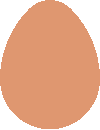

In [8]:
#teacher-only
from pytamaro import (
    Graphic, Color,
    rgb_color,
    circular_sector, triangle,
    above, overlay, rotate,
    compose, pin, bottom_center,
    show_graphic, save_graphic,
)
from math import sqrt

SHELL_COLOR = rgb_color(223, 151, 112)
YOLK_COLOR = rgb_color(239, 190, 71)
WHITE_COLOR = rgb_color(240, 235, 229)

def egg(width: float, color: Color) -> Graphic:
    return above(
        compose(
            pin(bottom_center,
                above(
                    rotate(45, circular_sector((1 - sqrt(2) / 2) * width, 90, color)),
                    rotate(180 + 45, triangle(sqrt(2) / 2 * width, sqrt(2) / 2 * width, 90, color))
                )
            ),
            pin(bottom_center,
                overlay(
                    circular_sector(width, 45, color),
                    rotate(180 - 45, circular_sector(width, 45, color))
                )
            )
        ),
        rotate(180, circular_sector(width / 2, 180, color))
    )

show_graphic(egg(100, SHELL_COLOR))
save_graphic("egg.svg", egg(100, SHELL_COLOR))


### Sliced Egg with Yolk

Implement the `sliced_egg` function to compose a sliced egg showing the egg white and egg yolk.

Either use and modify the code of the above `egg` function, so that it constructs two half-yolks (one for the top part, and one for the bottom part of the egg),
or call the `egg` function to build the egg white, and then superimpose the circular yellowish egg yolk, padded by an appropriate amoung (e.g., placing them above a <API>rectangle</API> with the appropriate height).

In [ ]:
from pytamaro import ellipse, rectangle

YOLK_COLOR = rgb_color(239, 190, 71)
WHITE_COLOR = rgb_color(240, 235, 229)

def sliced_egg(width: float) -> Graphic:
    return #TODO

show_graphic(sliced_egg(100))

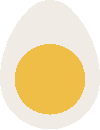

In [20]:
#teacher-only
from pytamaro import ellipse, rectangle

YOLK_COLOR = rgb_color(239, 190, 71)
WHITE_COLOR = rgb_color(240, 235, 229)

def sliced_egg(width: float) -> Graphic:
    return compose(
        pin(bottom_center, 
            above(
                ellipse(width * sqrt(2) / 2, width * sqrt(2) / 2, YOLK_COLOR),
                rectangle(0, width * (1 - sqrt(2) / 2) / 2, WHITE_COLOR)
             )
        ),
        pin(bottom_center, egg(width, WHITE_COLOR))
    )

show_graphic(sliced_egg(100))

from pytamaro import beside
save_graphic("egg.svg",
    beside(
        beside(
            beside(
                rotate(0, egg(100, SHELL_COLOR)), 
                rectangle(5, 0, WHITE_COLOR)
            ),
            beside(
                rotate(0, egg(100, WHITE_COLOR)),
                rectangle(5, 0, WHITE_COLOR)
            )
        ), 
        sliced_egg(100)
    )
)


### Easter Eggs

Now that you have a function to compose an egg, you may want to compose a nest full of colorful [Easter eggs](https://en.wikipedia.org/wiki/Easter_egg).